# Assignment 08: CNN + Transfer Learning with CIFAR-10

In this assignment, you will solve the same image-classification problem in **two ways**:

## Part A — Build a CNN from scratch
You will create a small CNN using convolution, ReLU, max pooling, flattening, and fully connected layers.

## Part B — Use transfer learning
You will load a pretrained **ResNet18**, replace its old classifier, train the new classifier, and then fine-tune the pretrained backbone.

The goal is to connect the main ideas from Class 20:

- convolution and feature maps
- pooling
- CNN feature extraction
- classification head
- pretrained backbone
- transfer learning
- fine-tuning

### Instructions

- Run all cells from top to bottom.
- Write code only in cells marked `# YOUR CODE HERE`.
- Read the hint above each task before writing code.
- Keep the test set untouched until the final evaluation of each completed model.

# Part A — CNN from Scratch

## 1. Imports and Configuration

Most setup code is already provided.

In [1]:
import copy
import random

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
SEED = 42

BATCH_SIZE_CNN = 128
CNN_EPOCHS = 10
CNN_LEARNING_RATE = 1e-3

VALIDATION_SIZE = 5_000
NUM_CLASSES = 10
DATA_DIR = "./data"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


## 2. CIFAR-10 Image Transformations

CIFAR-10 images are RGB images with shape `3 × 32 × 32`.

For training, we use a small amount of augmentation:

- random crop
- random horizontal flip

For validation and test, we only convert to tensors and normalize.

In [3]:
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

## 3. Load and Split the Dataset

The original CIFAR-10 training set contains 50,000 images.

We split it into:

- **training set** — used to update model parameters
- **validation set** — checked after every epoch

The official CIFAR-10 test set remains separate.

In [4]:
base_train_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
)

all_indices = np.arange(len(base_train_dataset))
all_labels = np.array(base_train_dataset.targets)

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
    stratify=all_labels,
)

full_train_augmented = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=train_transform,
)

full_train_eval = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=eval_transform,
)

test_dataset_cnn = datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=eval_transform,
)

train_dataset_cnn = Subset(
    full_train_augmented,
    train_indices,
)

val_dataset_cnn = Subset(
    full_train_eval,
    val_indices,
)

CLASS_NAMES = base_train_dataset.classes

print("Classes:", CLASS_NAMES)
print("Training images:", len(train_dataset_cnn))
print("Validation images:", len(val_dataset_cnn))
print("Test images:", len(test_dataset_cnn))

100%|██████████| 170M/170M [56:17<00:00, 50.5kB/s]


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training images: 45000
Validation images: 5000
Test images: 10000


## 4. Look at Sample Images

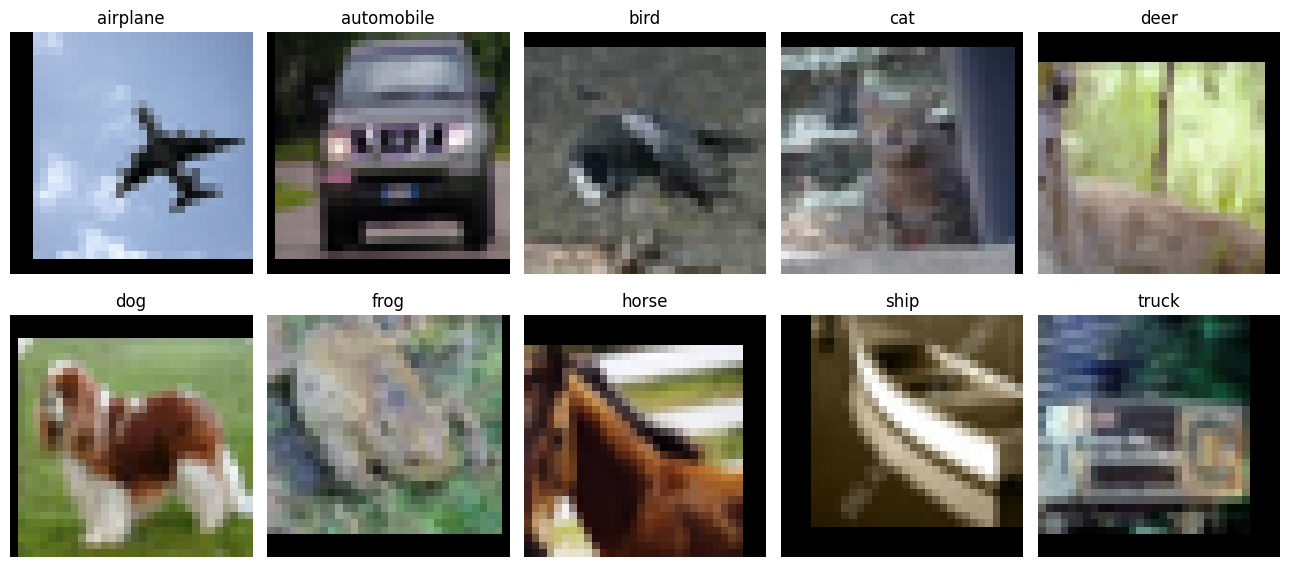

In [5]:
def denormalize_cifar(image_tensor):
    mean = torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR10_STD).view(3, 1, 1)

    image_tensor = image_tensor * std + mean
    image_tensor = image_tensor.clamp(0, 1)

    return image_tensor.permute(1, 2, 0).numpy()


samples = {}

for image, label in train_dataset_cnn:
    if label not in samples:
        samples[label] = image

    if len(samples) == NUM_CLASSES:
        break


fig, axes = plt.subplots(2, 5, figsize=(13, 6))
axes = axes.flatten()

for label in range(NUM_CLASSES):
    axes[label].imshow(denormalize_cifar(samples[label]))
    axes[label].set_title(CLASS_NAMES[label])
    axes[label].axis("off")

plt.tight_layout()
plt.show()

## 5. Create DataLoaders

In [6]:
loader_options = {
    "num_workers": 2,
    "pin_memory": torch.cuda.is_available(),
}

train_loader_cnn = DataLoader(
    train_dataset_cnn,
    batch_size=BATCH_SIZE_CNN,
    shuffle=True,
    **loader_options,
)

val_loader_cnn = DataLoader(
    val_dataset_cnn,
    batch_size=BATCH_SIZE_CNN,
    shuffle=False,
    **loader_options,
)

test_loader_cnn = DataLoader(
    test_dataset_cnn,
    batch_size=BATCH_SIZE_CNN,
    shuffle=False,
    **loader_options,
)

images, labels = next(iter(train_loader_cnn))

print("Image batch:", images.shape)
print("Label batch:", labels.shape)

Image batch: torch.Size([128, 3, 32, 32])
Label batch: torch.Size([128])


## 6. Build a Small CNN

We will use this architecture:

```text
Input [3, 32, 32]

Conv2d(3 → 32, 3×3, padding=1)
ReLU
MaxPool2d(2)
        ↓
[32, 16, 16]

Conv2d(32 → 64, 3×3, padding=1)
ReLU
MaxPool2d(2)
        ↓
[64, 8, 8]

Conv2d(64 → 128, 3×3, padding=1)
ReLU
MaxPool2d(2)
        ↓
[128, 4, 4]

Flatten
Linear(128×4×4 → 128)
ReLU
Linear(128 → 10 logits)
```

### Your task

Complete only the `forward()` method.

Hint:

1. send `x` through `self.features`
2. send the result through `self.classifier`
3. return the logits

In [7]:
class CIFAR10CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=3,
                padding=1,
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1,
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1,
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x) 
        return x

## 7. Check the Model

The model should return one logit for each of the 10 CIFAR-10 classes.

For a batch of 4 images, the expected output shape is:

`[4, 10]`

In [8]:
cnn_model = CIFAR10CNN(
    num_classes=NUM_CLASSES,
).to(device)

dummy_images = torch.randn(
    4,
    3,
    32,
    32,
).to(device)

dummy_output = cnn_model(dummy_images)

print("Input shape :", dummy_images.shape)
print("Output shape:", dummy_output.shape)


assert dummy_output.shape == (4, NUM_CLASSES)

Input shape : torch.Size([4, 3, 32, 32])
Output shape: torch.Size([4, 10])


## 8. Complete One Training Step

Inside each mini-batch, the training step follows the same five operations from Class 19:

```text
zero gradients
→ forward pass
→ compute loss
→ backward pass
→ update parameters
```

### Your task

Fill the marked section.

Hint: you need these five lines in the correct order:

```python
optimizer.zero_grad()
logits = model(images)
loss = criterion(logits, labels)
loss.backward()
optimizer.step()
```

In [9]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device,
):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(
            device,
            non_blocking=True,
        )
        labels = labels.to(
            device,
            non_blocking=True,
        )

        # YOUR CODE HERE
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels) 
        loss.backward()
        optimizer.step()


        ########

        predictions = logits.argmax(dim=1)

        running_loss += (
            loss.item() * images.size(0)
        )
        correct += (
            predictions == labels
        ).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

## 9. Evaluation

Evaluation uses a forward pass only.

There is:

- no `loss.backward()`
- no `optimizer.step()`
- no parameter update

In [10]:
def evaluate(
    model,
    loader,
    criterion,
    device,
):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(
                device,
                non_blocking=True,
            )
            labels = labels.to(
                device,
                non_blocking=True,
            )

            logits = model(images)
            loss = criterion(
                logits,
                labels,
            )

            predictions = logits.argmax(
                dim=1
            )

            running_loss += (
                loss.item() * images.size(0)
            )
            correct += (
                predictions == labels
            ).sum().item()
            total += labels.size(0)

    loss = running_loss / total
    accuracy = correct / total

    return loss, accuracy

## 10. Loss Function and Optimizer

This is a 10-class classification problem.

### Your task

Create:

- `CrossEntropyLoss`
- Adam optimizer for all CNN parameters

Use:

`learning rate = CNN_LEARNING_RATE`

### Hint

Complete the blanks:

```python
criterion = nn.________()

cnn_optimizer = optim.Adam(
    ________.parameters(),
    lr=________
)
```


In [11]:
# YOUR CODE HERE
criterion = nn.CrossEntropyLoss()
cnn_optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=CNN_LEARNING_RATE,
)

## 11. Train the CNN

The validation set is checked after every epoch.

The best model is selected using **validation accuracy**, not test accuracy.

In [12]:
cnn_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

best_cnn_val_accuracy = -1.0
best_cnn_state = None
best_cnn_epoch = 0

for epoch in range(
    1,
    CNN_EPOCHS + 1,
):
    train_loss, train_accuracy = train_one_epoch(
        cnn_model,
        train_loader_cnn,
        criterion,
        cnn_optimizer,
        device,
    )

    val_loss, val_accuracy = evaluate(
        cnn_model,
        val_loader_cnn,
        criterion,
        device,
    )

    cnn_history["train_loss"].append(
        train_loss
    )
    cnn_history["train_accuracy"].append(
        train_accuracy
    )
    cnn_history["val_loss"].append(
        val_loss
    )
    cnn_history["val_accuracy"].append(
        val_accuracy
    )

    if val_accuracy > best_cnn_val_accuracy:
        best_cnn_val_accuracy = val_accuracy
        best_cnn_epoch = epoch
        best_cnn_state = copy.deepcopy(
            cnn_model.state_dict()
        )

    print(
        f"Epoch {epoch:02d}/{CNN_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy * 100:.2f}%"
    )

cnn_model.load_state_dict(
    best_cnn_state
)

print()
print(
    "Best epoch:",
    best_cnn_epoch,
)
print(
    f"Best validation accuracy: "
    f"{best_cnn_val_accuracy * 100:.2f}%"
)

Epoch 01/10 | Train Loss: 1.6468 | Train Acc: 39.83% | Val Loss: 1.3265 | Val Acc: 51.24%
Epoch 02/10 | Train Loss: 1.2978 | Train Acc: 53.39% | Val Loss: 1.0980 | Val Acc: 61.48%
Epoch 03/10 | Train Loss: 1.1147 | Train Acc: 60.39% | Val Loss: 0.9549 | Val Acc: 66.20%
Epoch 04/10 | Train Loss: 0.9903 | Train Acc: 64.94% | Val Loss: 0.8877 | Val Acc: 69.38%
Epoch 05/10 | Train Loss: 0.9037 | Train Acc: 68.20% | Val Loss: 0.8516 | Val Acc: 69.64%
Epoch 06/10 | Train Loss: 0.8519 | Train Acc: 70.02% | Val Loss: 0.7613 | Val Acc: 73.52%
Epoch 07/10 | Train Loss: 0.7913 | Train Acc: 72.30% | Val Loss: 0.7314 | Val Acc: 73.74%
Epoch 08/10 | Train Loss: 0.7599 | Train Acc: 73.33% | Val Loss: 0.6988 | Val Acc: 74.94%
Epoch 09/10 | Train Loss: 0.7307 | Train Acc: 74.47% | Val Loss: 0.6817 | Val Acc: 76.24%
Epoch 10/10 | Train Loss: 0.6962 | Train Acc: 75.70% | Val Loss: 0.6551 | Val Acc: 77.32%

Best epoch: 10
Best validation accuracy: 77.32%


## 12. Training Curves

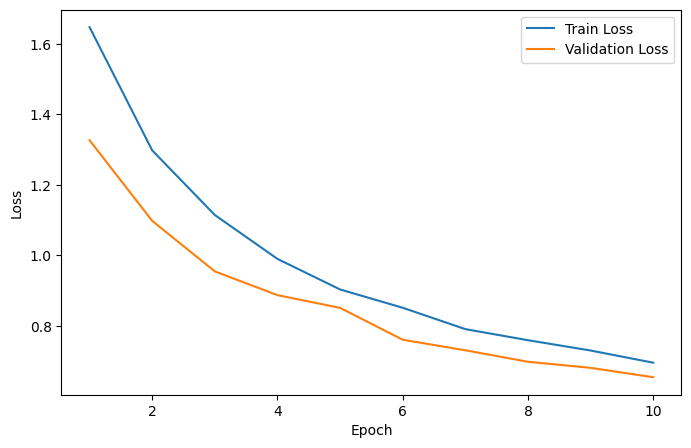

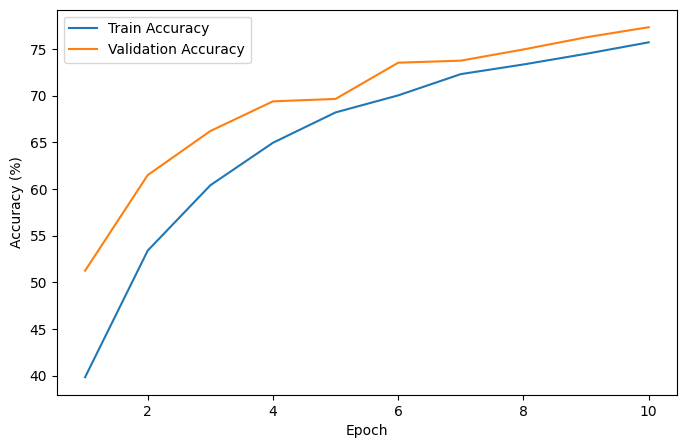

In [13]:
cnn_epochs = range(
    1,
    CNN_EPOCHS + 1,
)

plt.figure(figsize=(8, 5))
plt.plot(
    cnn_epochs,
    cnn_history["train_loss"],
    label="Train Loss",
)
plt.plot(
    cnn_epochs,
    cnn_history["val_loss"],
    label="Validation Loss",
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    cnn_epochs,
    np.array(
        cnn_history["train_accuracy"]
    ) * 100,
    label="Train Accuracy",
)
plt.plot(
    cnn_epochs,
    np.array(
        cnn_history["val_accuracy"]
    ) * 100,
    label="Validation Accuracy",
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.show()

# Part B — Transfer Learning with ResNet18

Now solve the same CIFAR-10 classification problem using a pretrained CNN.

The workflow is:

```text
pretrained ResNet18 backbone
+
new 10-class classifier
=
our transfer-learning model
```

We will first:

1. freeze the pretrained backbone
2. train only the new classifier

Then we will:

3. unfreeze pretrained parameters
4. fine-tune them with a smaller learning rate

> **Training note:** The transfer-learning epoch counts are intentionally small so everyone can complete the assignment on a GPU. The goal is to practice the workflow, not maximize CIFAR-10 accuracy.

## 14. ImageNet Transforms for ResNet18

The pretrained ResNet18 expects ImageNet-style inputs.

CIFAR-10 images are only `32×32`, so we resize them to `224×224`.

We also use the ImageNet mean and standard deviation expected by the pretrained weights.

In [14]:
IMAGENET_MEAN = (
    0.485,
    0.456,
    0.406,
)

IMAGENET_STD = (
    0.229,
    0.224,
    0.225,
)

transfer_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD,
    ),
])

transfer_eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD,
    ),
])

## 15. Create Transfer-Learning DataLoaders

We reuse the **same train/validation split** as Part A.

Only the transforms are different.

In [15]:
transfer_train_full = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=transfer_train_transform,
)

transfer_val_full = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=transfer_eval_transform,
)

transfer_test_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=False,
    transform=transfer_eval_transform,
)

transfer_train_dataset = Subset(
    transfer_train_full,
    train_indices,
)

transfer_val_dataset = Subset(
    transfer_val_full,
    val_indices,
)

BATCH_SIZE_TRANSFER = 64

transfer_train_loader = DataLoader(
    transfer_train_dataset,
    batch_size=BATCH_SIZE_TRANSFER,
    shuffle=True,
    **loader_options,
)

transfer_val_loader = DataLoader(
    transfer_val_dataset,
    batch_size=BATCH_SIZE_TRANSFER,
    shuffle=False,
    **loader_options,
)

transfer_test_loader = DataLoader(
    transfer_test_dataset,
    batch_size=BATCH_SIZE_TRANSFER,
    shuffle=False,
    **loader_options,
)

images, labels = next(
    iter(transfer_train_loader)
)

print("Image batch:", images.shape)
print("Label batch:", labels.shape)

Image batch: torch.Size([64, 3, 224, 224])
Label batch: torch.Size([64])


## 16. Load a Pretrained ResNet18

ResNet18 was pretrained on ImageNet.

Its original classifier predicts 1000 ImageNet classes.

### Your task

1. freeze all pretrained parameters
2. read the number of inputs to the old classifier
3. replace the old classifier with a new `Linear` layer that outputs 10 logits

Important:

Freeze the pretrained model **before** replacing `model.fc`.  
The new classifier will then remain trainable.

### Hint

```python
# 1. Loop through all pretrained parameters
#    and set:
param.requires_grad = False

# 2. The old classifier is:
transfer_model.fc

# 3. Its input size is available from:
transfer_model.fc.in_features

# 4. Replace the old classifier with:
nn.Linear(input_size, NUM_CLASSES)
```


In [16]:
weights = models.ResNet18_Weights.DEFAULT

transfer_model = models.resnet18(
    weights=weights
)

print("Original classifier:")
print(transfer_model.fc)

# YOUR CODE HERE
for param in transfer_model.parameters():
    param.requires_grad = False

in_features = transfer_model.fc.in_features
transfer_model.fc = nn.Linear(in_features, NUM_CLASSES)



transfer_model = transfer_model.to(
    device
)

print("\nNew classifier:")
print(transfer_model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 224MB/s]

Original classifier:
Linear(in_features=512, out_features=1000, bias=True)

New classifier:
Linear(in_features=512, out_features=10, bias=True)


In [17]:
assert transfer_model.fc.out_features == NUM_CLASSES

assert all(
    not param.requires_grad
    for name, param in transfer_model.named_parameters()
    if not name.startswith("fc.")
)

assert all(
    param.requires_grad
    for param in transfer_model.fc.parameters()
)

print("Backbone frozen correctly.")
print("New classifier is trainable.")

Backbone frozen correctly.
New classifier is trainable.


## 17. Check What Is Trainable

At this point:

- pretrained backbone → frozen
- new classifier → trainable

In [18]:
trainable_parameters = sum(
    p.numel()
    for p in transfer_model.parameters()
    if p.requires_grad
)

total_parameters = sum(
    p.numel()
    for p in transfer_model.parameters()
)

print(
    f"Trainable parameters: "
    f"{trainable_parameters:,}"
)
print(
    f"Total parameters: "
    f"{total_parameters:,}"
)
print(
    f"Frozen parameters: "
    f"{total_parameters - trainable_parameters:,}"
)

Trainable parameters: 5,130
Total parameters: 11,181,642
Frozen parameters: 11,176,512


## 18. Training Helper for a Frozen Backbone

ResNet contains BatchNorm layers.

When the pretrained backbone is frozen, we also keep its BatchNorm running statistics fixed.

The helper below is provided for you.

In [19]:
def train_transfer_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device,
    backbone_frozen,
):
    if backbone_frozen:
        model.eval()
        model.fc.train()
    else:
        model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(
            device,
            non_blocking=True,
        )
        labels = labels.to(
            device,
            non_blocking=True,
        )

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(
            logits,
            labels,
        )

        loss.backward()
        optimizer.step()

        predictions = logits.argmax(
            dim=1
        )

        running_loss += (
            loss.item() * images.size(0)
        )
        correct += (
            predictions == labels
        ).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

## 19. Phase 1 — Train the New Classifier

The pretrained backbone remains frozen.

Only the new classifier learns from scratch.

### Your task

Create an Adam optimizer for:

`transfer_model.fc.parameters()`

Use:

`learning rate = 1e-3`

### Hint

Complete the blanks:

```python
transfer_head_optimizer = optim.Adam(
    transfer_model.____.parameters(),
    lr=____
)
```


In [20]:
TRANSFER_HEAD_EPOCHS = 2

# YOUR CODE HERE

transfer_head_optimizer = optim.Adam(
    transfer_model.fc.parameters(),
    lr=1e-3,
)



In [21]:
transfer_history_phase1 = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

best_transfer_val_accuracy = -1.0
best_transfer_state = None
best_transfer_epoch = ""

print("Phase 1: train the new classifier")
print("-" * 60)

for epoch in range(
    1,
    TRANSFER_HEAD_EPOCHS + 1,
):
    train_loss, train_accuracy = (
        train_transfer_one_epoch(
            transfer_model,
            transfer_train_loader,
            criterion,
            transfer_head_optimizer,
            device,
            backbone_frozen=True,
        )
    )

    val_loss, val_accuracy = evaluate(
        transfer_model,
        transfer_val_loader,
        criterion,
        device,
    )

    transfer_history_phase1[
        "train_loss"
    ].append(train_loss)

    transfer_history_phase1[
        "train_accuracy"
    ].append(train_accuracy)

    transfer_history_phase1[
        "val_loss"
    ].append(val_loss)

    transfer_history_phase1[
        "val_accuracy"
    ].append(val_accuracy)

    if (
        val_accuracy
        > best_transfer_val_accuracy
    ):
        best_transfer_val_accuracy = (
            val_accuracy
        )
        best_transfer_epoch = (
            f"Phase 1, epoch {epoch}"
        )
        best_transfer_state = copy.deepcopy(
            transfer_model.state_dict()
        )

    print(
        f"Epoch {epoch:02d}/"
        f"{TRANSFER_HEAD_EPOCHS} | "
        f"Train Acc: "
        f"{train_accuracy * 100:.2f}% | "
        f"Val Acc: "
        f"{val_accuracy * 100:.2f}%"
    )

Phase 1: train the new classifier
------------------------------------------------------------
Epoch 01/2 | Train Acc: 81.72% | Val Acc: 86.48%
Epoch 02/2 | Train Acc: 86.79% | Val Acc: 86.84%


### Start Fine-Tuning from the Best Phase-1 Model

Phase 1 may not improve every epoch. Before fine-tuning, restore the model state that achieved the best validation accuracy during classifier training.

In [22]:
transfer_model.load_state_dict(
    best_transfer_state
)

print("Restored best Phase-1 model before fine-tuning.")

Restored best Phase-1 model before fine-tuning.


## 20. Phase 2 — Fine-Tune the Pretrained Backbone

Fine-tuning means updating **pretrained parameters**.

We will unfreeze the pretrained backbone and continue training with a much smaller learning rate.

The new classifier continues training too.

### Your task

Set the pretrained backbone parameters to:

`requires_grad = True`

Do not replace the classifier again.

### Hint

```python
# Loop through:
transfer_model.named_parameters()

# Classifier parameter names start with:
"fc."

# For parameters whose names do NOT start with "fc.",
# set:
param.requires_grad = True
```


In [23]:
# YOUR CODE HERE

for name, param in transfer_model.named_parameters():
    if not name.startswith("fc."):
        param.requires_grad=True


In [24]:
assert all(
    param.requires_grad
    for name, param in transfer_model.named_parameters()
    if not name.startswith("fc.")
)

print("Pretrained backbone parameters are now trainable.")

Pretrained backbone parameters are now trainable.


### Fine-Tuning Optimizer

We use two learning rates:

- pretrained backbone → `1e-5`
- new classifier → `1e-4`

The pretrained backbone uses the smaller learning rate because it already contains useful learned features.

The optimizer code is provided.

In [25]:
backbone_parameters = [
    param
    for name, param in transfer_model.named_parameters()
    if not name.startswith("fc.")
]

fine_tune_optimizer = optim.Adam([
    {
        "params": backbone_parameters,
        "lr": 1e-5,
    },
    {
        "params": transfer_model.fc.parameters(),
        "lr": 1e-4,
    },
])

TRANSFER_FINE_TUNE_EPOCHS = 1

In [26]:
transfer_history_phase2 = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

print("Phase 2: fine-tune pretrained parameters")
print("-" * 60)

for epoch in range(
    1,
    TRANSFER_FINE_TUNE_EPOCHS + 1,
):
    train_loss, train_accuracy = (
        train_transfer_one_epoch(
            transfer_model,
            transfer_train_loader,
            criterion,
            fine_tune_optimizer,
            device,
            backbone_frozen=False,
        )
    )

    val_loss, val_accuracy = evaluate(
        transfer_model,
        transfer_val_loader,
        criterion,
        device,
    )

    transfer_history_phase2[
        "train_loss"
    ].append(train_loss)

    transfer_history_phase2[
        "train_accuracy"
    ].append(train_accuracy)

    transfer_history_phase2[
        "val_loss"
    ].append(val_loss)

    transfer_history_phase2[
        "val_accuracy"
    ].append(val_accuracy)

    if (
        val_accuracy
        > best_transfer_val_accuracy
    ):
        best_transfer_val_accuracy = (
            val_accuracy
        )
        best_transfer_epoch = (
            f"Phase 2, epoch {epoch}"
        )
        best_transfer_state = copy.deepcopy(
            transfer_model.state_dict()
        )

    print(
        f"Epoch {epoch:02d}/"
        f"{TRANSFER_FINE_TUNE_EPOCHS} | "
        f"Train Acc: "
        f"{train_accuracy * 100:.2f}% | "
        f"Val Acc: "
        f"{val_accuracy * 100:.2f}%"
    )

Phase 2: fine-tune pretrained parameters
------------------------------------------------------------
Epoch 01/1 | Train Acc: 85.54% | Val Acc: 90.28%


## 21. Restore the Best Transfer-Learning Model

The best state is selected using validation accuracy.

In [27]:
transfer_model.load_state_dict(
    best_transfer_state
)

print(
    "Best transfer-learning model:",
    best_transfer_epoch,
)

print(
    f"Best validation accuracy: "
    f"{best_transfer_val_accuracy * 100:.2f}%"
)

Best transfer-learning model: Phase 2, epoch 1
Best validation accuracy: 90.28%


## 22. Final Test — Transfer Learning

The transfer-learning model is now finalized.

Evaluate it on the test set once.

In [28]:
transfer_test_loss, transfer_test_accuracy = evaluate(
    transfer_model,
    transfer_test_loader,
    criterion,
    device,
)

print(
    f"Transfer Test Loss: "
    f"{transfer_test_loss:.4f}"
)

print(
    f"Transfer Test Accuracy: "
    f"{transfer_test_accuracy * 100:.2f}%"
)

Transfer Test Loss: 0.3110
Transfer Test Accuracy: 89.61%


# Part C — Final Test, Comparison, and Prediction Inspection

Both models have now been finalized using **validation performance only**.

The test set has not been used to train, tune, or select either model.

Now evaluate both finalized models on the test set.


## 23. Final Test — Evaluate Both Models

Evaluate the final CNN-from-scratch model and the final transfer-learning model on the test set.

This is the first test-set evaluation for both finalized models.


In [29]:
cnn_test_loss, cnn_test_accuracy = evaluate(
    cnn_model,
    test_loader_cnn,
    criterion,
    device,
)

transfer_test_loss, transfer_test_accuracy = evaluate(
    transfer_model,
    transfer_test_loader,
    criterion,
    device,
)

print("CNN from scratch")
print(f"Test Loss    : {cnn_test_loss:.4f}")
print(f"Test Accuracy: {cnn_test_accuracy * 100:.2f}%")

print("\nTransfer learning")
print(f"Test Loss    : {transfer_test_loss:.4f}")
print(f"Test Accuracy: {transfer_test_accuracy * 100:.2f}%")


CNN from scratch
Test Loss    : 0.6671
Test Accuracy: 76.98%

Transfer learning
Test Loss    : 0.3110
Test Accuracy: 89.61%


## 24. Confusion Matrix — Transfer-Learning Model

Inspect which CIFAR-10 classes are commonly confused.

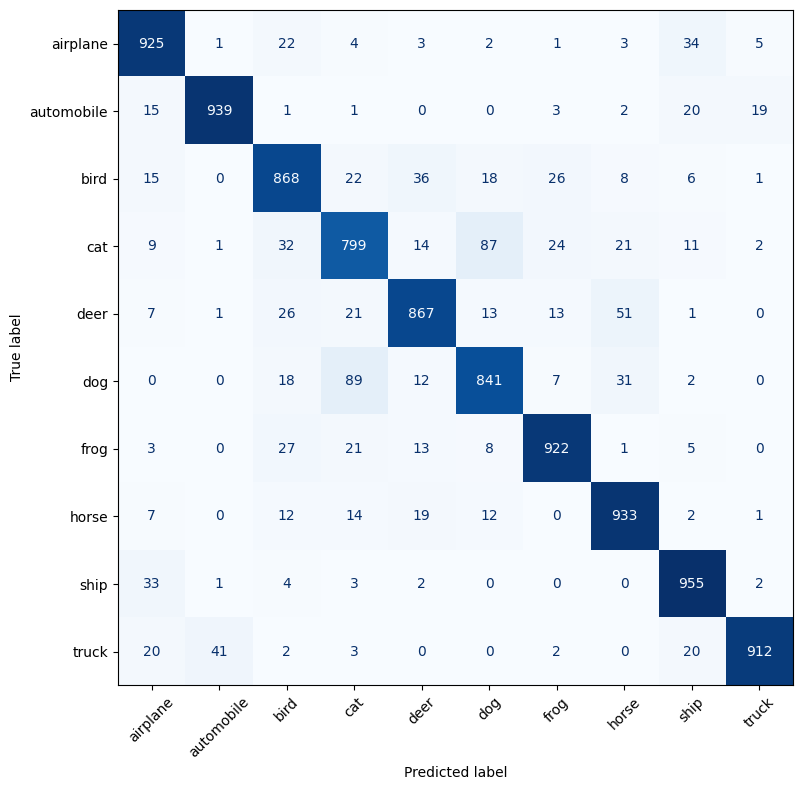

In [30]:
def collect_predictions(
    model,
    loader,
    device,
):
    model.eval()

    all_predictions = []
    all_labels = []

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(
                device,
                non_blocking=True,
            )

            logits = model(images)

            predictions = logits.argmax(
                dim=1
            ).cpu()

            all_predictions.extend(
                predictions.numpy()
            )
            all_labels.extend(
                labels.numpy()
            )

    return (
        np.array(all_predictions),
        np.array(all_labels),
    )


transfer_predictions, transfer_labels = (
    collect_predictions(
        transfer_model,
        transfer_test_loader,
        device,
    )
)

cm = confusion_matrix(
    transfer_labels,
    transfer_predictions,
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES,
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
)

plt.tight_layout()
plt.show()

## 25. Correct and Misclassified Examples

Look at real predictions instead of only the accuracy number.

The first row shows correctly classified test images.

The second row shows misclassified test images.

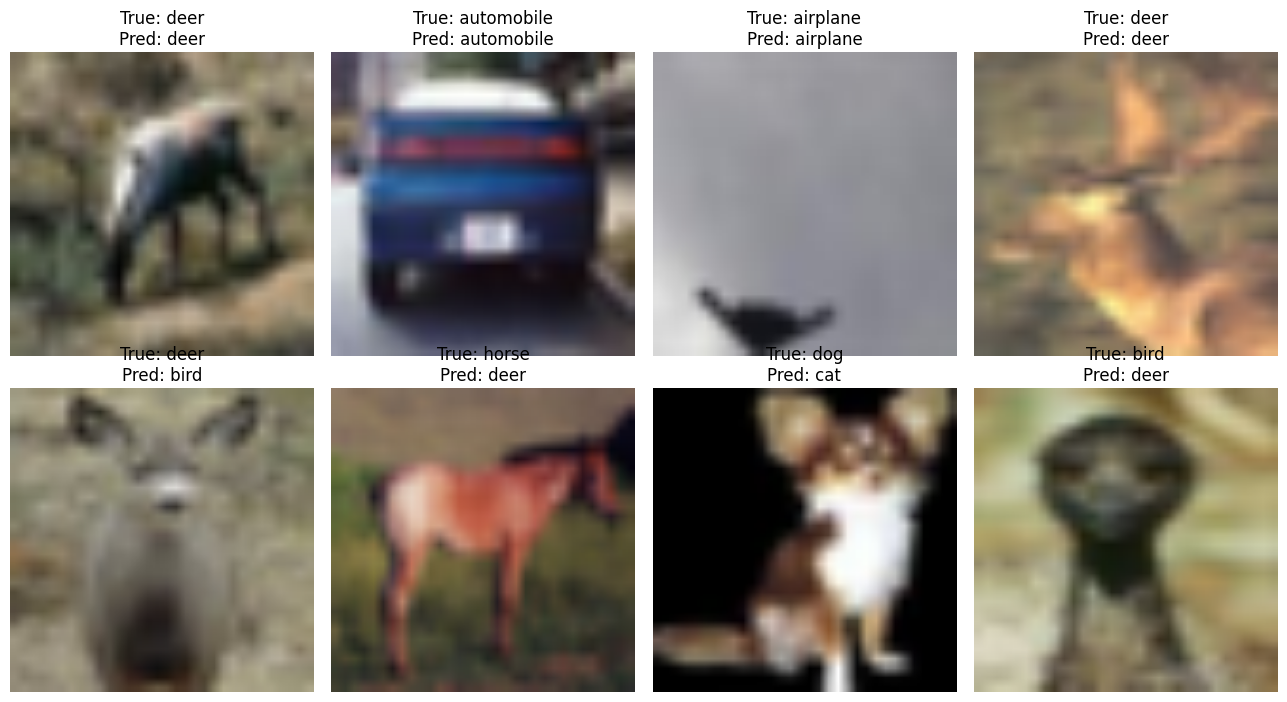

In [31]:
correct_indices = np.where(
    transfer_predictions
    == transfer_labels
)[0].tolist()

wrong_indices = np.where(
    transfer_predictions
    != transfer_labels
)[0].tolist()

rng = np.random.default_rng(SEED)

selected_correct = rng.choice(
    correct_indices,
    size=min(4, len(correct_indices)),
    replace=False,
)

selected_wrong = rng.choice(
    wrong_indices,
    size=min(4, len(wrong_indices)),
    replace=False,
)

fig, axes = plt.subplots(
    2,
    4,
    figsize=(13, 7),
)

for col in range(4):
    axis = axes[0, col]

    if col < len(selected_correct):
        index = selected_correct[col]

        image, true_label = (
            transfer_test_dataset[index]
        )

        predicted_label = (
            transfer_predictions[index]
        )

        # Undo ImageNet normalization for display.
        mean = torch.tensor(
            IMAGENET_MEAN
        ).view(3, 1, 1)

        std = torch.tensor(
            IMAGENET_STD
        ).view(3, 1, 1)

        display_image = (
            image.cpu() * std + mean
        ).clamp(0, 1)

        axis.imshow(
            display_image.permute(
                1,
                2,
                0,
            )
        )

        axis.set_title(
            f"True: "
            f"{CLASS_NAMES[true_label]}\n"
            f"Pred: "
            f"{CLASS_NAMES[predicted_label]}"
        )

    axis.axis("off")


for col in range(4):
    axis = axes[1, col]

    if col < len(selected_wrong):
        index = selected_wrong[col]

        image, true_label = (
            transfer_test_dataset[index]
        )

        predicted_label = (
            transfer_predictions[index]
        )

        mean = torch.tensor(
            IMAGENET_MEAN
        ).view(3, 1, 1)

        std = torch.tensor(
            IMAGENET_STD
        ).view(3, 1, 1)

        display_image = (
            image.cpu() * std + mean
        ).clamp(0, 1)

        axis.imshow(
            display_image.permute(
                1,
                2,
                0,
            )
        )

        axis.set_title(
            f"True: "
            f"{CLASS_NAMES[true_label]}\n"
            f"Pred: "
            f"{CLASS_NAMES[predicted_label]}"
        )

    axis.axis("off")


axes[0, 0].set_ylabel(
    "Correct",
    fontsize=12,
)

axes[1, 0].set_ylabel(
    "Misclassified",
    fontsize=12,
)

plt.tight_layout()
plt.show()